In [1]:
#| echo: false
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(19)

# The Poisson Process

## Motivation: car crashes

::: {.callout-note}
## Question

Crashes at a busy intersection occur at *random times*. How should we model

- **when** crashes happen, and
- **how many** crashes happen in a given window of time?
:::

. . .

::: {.callout-tip}
## Reasonable modeling assumptions

- Crashes are equally likely at any moment (no rush hour, in this simple model).
- What happens in one window of time tells us nothing about a disjoint window.
- In a very short window, we see at most one crash.

This is the **Bernoulli process** with time chopped into infinitely many tiny slots.
:::

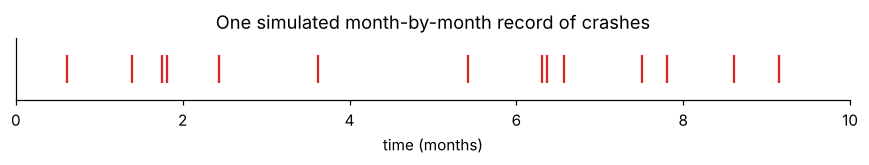

In [2]:
#| fig-height: 1.6
lam, T = 1.5, 10          # crashes per month, months observed
t = np.cumsum(rng.exponential(1 / lam, size=100)); t = t[t <= T]
fig, ax = plt.subplots(figsize=(8, 1.6))
ax.eventplot(t, lineoffsets=0, linelengths=0.8, color="C3")
ax.set_yticks([]); ax.set_xlim(0, T); ax.set_xlabel("time (months)")
ax.set_title("One simulated month-by-month record of crashes")
plt.tight_layout(); plt.show()

## Poisson process: definition

::: {.callout-note}
## Definition

An arrival process with **arrival rate** $\lambda>0$ (arrivals per unit time). Let $P(k,\tau)$ be the probability of exactly $k$ arrivals in an interval of length $\tau$. The process satisfies:

1. **Time homogeneity:** $P(k,\tau)$ is the same for every interval of length $\tau$.
2. **Independence:** the numbers of arrivals in disjoint intervals are independent.
3. **Small intervals** (length $\delta\to 0$):
$$P(0,\delta)=1-\lambda\delta+o(\delta),\qquad P(1,\delta)=\lambda\delta+o(\delta),\qquad P(k\ge2,\delta)=o(\delta).$$
:::

. . .

::: {.callout-warning}
## Reading the definition

$\lambda\delta$ plays the role of the Bernoulli success probability $p$ in a tiny slot, and $o(\delta)$ means "negligible compared to $\delta$".
:::

# Number of Arrivals in an Interval

## From Bernoulli to Poisson

::: {.callout-note}
## Derivation

Chop $[0,\tau]$ into $n=\tau/\delta$ slots. Each slot is an independent Bernoulli trial with success probability
$$p=\lambda\delta=\frac{\lambda\tau}{n},$$
so the number of arrivals $N_\tau\sim\text{Binomial}(n,p)$.
:::

. . .

::: {.callout-warning}
## Let $n\to\infty$ with $np=\lambda\tau$ fixed

$$\binom{n}{k}p^k(1-p)^{n-k}\;\longrightarrow\;\frac{(\lambda\tau)^k}{k!}e^{-\lambda\tau}.$$
We saw this limit in Lecture 3; here is where it comes from.
:::

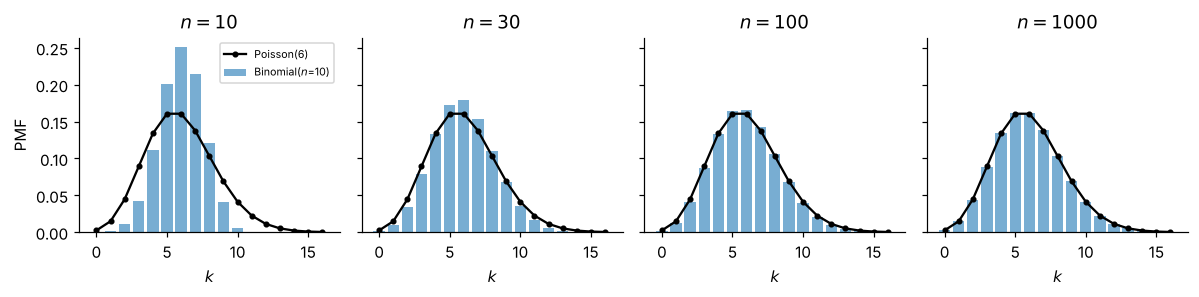

In [3]:
#| fig-height: 3.4
mu = 6.0      # lambda * tau
k = np.arange(0, 17)
fig, axs = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
for ax, n in zip(axs, [10, 30, 100, 1000]):
    ax.bar(k, stats.binom.pmf(k, n, mu / n), color="C0", alpha=0.6, label=f"Binomial($n$={n})")
    ax.plot(k, stats.poisson.pmf(k, mu), "ko-", ms=3, label="Poisson(6)")
    ax.set_title(f"$n={n}$"); ax.set_xlabel("$k$")
axs[0].set_ylabel("PMF"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Poisson PMF, mean, and variance

::: {.callout-note}
## Poisson PMF for the number of arrivals in time $\tau$

$$P(N_\tau=k)=P(k,\tau)=\frac{(\lambda\tau)^k e^{-\lambda\tau}}{k!},\qquad k=0,1,2,\ldots$$
:::

. . .

::: {.callout-tip}
## Mean and variance

$$E[N_\tau]=\lambda\tau,\qquad \text{Var}(N_\tau)=\lambda\tau.$$
These match the Binomial values $np=\lambda\tau$ and $np(1-p)\to\lambda\tau$ in the limit $p\to0$.
:::

In [4]:
lam, tau = 2.0, 3.0
N = rng.poisson(lam * tau, size=200_000)
print("E[N_tau]   :", N.mean(), "   theory", lam * tau)
print("Var(N_tau) :", N.var(),  "   theory", lam * tau)

E[N_tau]   : 5.99428    theory 6.0
Var(N_tau) : 6.044277281599999    theory 6.0


# Time of the First Arrival

## Tail probability, CDF, and PDF

::: {.callout-note}
## Tail probability

Let $T_1$ be the time of the first arrival. No arrival by time $t$ means zero arrivals in $[0,t]$:
$$P(T_1>t)=P(0,t)=e^{-\lambda t},\qquad t\ge0.$$
:::

. . .

::: {.callout-warning}
## CDF $\to$ PDF

$$F_{T_1}(t)=1-e^{-\lambda t}\quad\Longrightarrow\quad f_{T_1}(t)=\frac{d}{dt}F_{T_1}(t)=\lambda e^{-\lambda t},\quad t\ge0.$$
:::

. . .

::: {.callout-tip}
## Conclusion

$T_1\sim\text{Exponential}(\lambda)$, with
$$E[T_1]=\frac1\lambda,\qquad\text{Var}(T_1)=\frac1{\lambda^2}.$$
:::

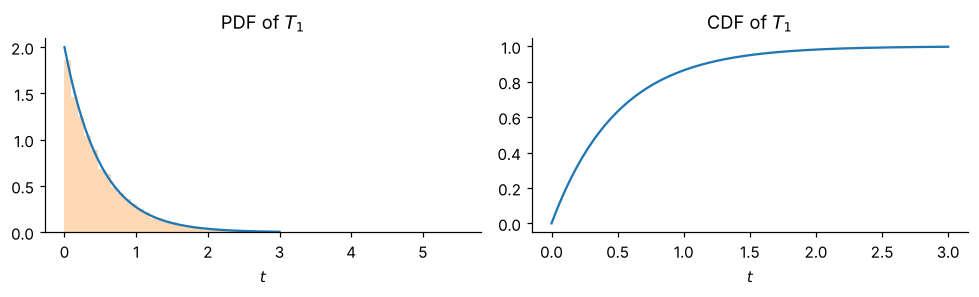

mean, var of simulated T1: 0.5033326042609567 0.2510625903968063  theory: 0.5 0.25


In [5]:
#| fig-height: 3
lam = 2.0
x = np.linspace(0, 3, 300)
fig, axs = plt.subplots(1, 2, figsize=(9, 2.8))
axs[0].plot(x, lam * np.exp(-lam * x)); axs[0].set_title("PDF of $T_1$")
axs[1].plot(x, 1 - np.exp(-lam * x)); axs[1].set_title("CDF of $T_1$")
sim = rng.exponential(1 / lam, size=20_000)      # time of first arrival = first interarrival gap
axs[0].hist(sim, bins=60, density=True, alpha=0.3, color="C1")
for a in axs: a.set_xlabel("$t$")
plt.tight_layout(); plt.show()
print("mean, var of simulated T1:", sim.mean(), sim.var(), " theory:", 1/lam, 1/lam**2)

# Summary: Bernoulli vs. Poisson

## Two descriptions of arrivals

| | **Bernoulli process** | **Poisson process** |
|---|---|---|
| Times of arrival | discrete: $i=1,2,\ldots$ | continuous: $t\ge0$ |
| Arrival rate | $p$ per trial | $\lambda$ per unit time |
| PMF of # of arrivals | Binomial$(n,p)$ | Poisson$(\lambda\tau)$ |
| Interarrival time | Geometric$(p)$ | Exponential$(\lambda)$ |
| Mean interarrival time | $1/p$ | $1/\lambda$ |
| Time of $k$th arrival | Pascal$(k,p)$ | Erlang$(k,\lambda)$ |

. . .

::: {.callout-tip}
## Take-away

Poisson is the continuous-time limit of Bernoulli: **Binomial $\to$ Poisson** and **Geometric $\to$ Exponential**.
:::

## Example: emails

::: {.callout-warning}
## Example

Emails arrive as a Poisson process with rate $\lambda=5$ per hour.

(a) What is the probability of no emails in the next 30 minutes?

(b) What is the probability of exactly 3 emails in the next hour?

(c) What is the expected wait until the next email?
:::

. . .

::: {.callout-note}
## Solution

(a) $\lambda\tau=5(0.5)=2.5$, so $P(N=0)=e^{-2.5}\approx0.082$.

(b) $\lambda\tau=5$, so $P(N=3)=\dfrac{5^3e^{-5}}{3!}\approx0.140$.

(c) $E[T_1]=1/\lambda=1/5$ hour $=12$ minutes.
:::

In [6]:
print("(a)", stats.poisson.pmf(0, 2.5))
print("(b)", stats.poisson.pmf(3, 5))
print("(c)", 60 / 5, "minutes")

(a) 0.0820849986238988
(b) 0.1403738958142805
(c) 12.0 minutes


# Independence and Memorylessness

## Fresh start

::: {.callout-note}
## Fact

For any time $t$, the arrivals after $t$ form a new Poisson process with the same rate $\lambda$, **independent of everything that happened before $t$**.
:::

. . .

::: {.callout-warning}
## Memorylessness of the exponential

$$P(T_1>t+s\mid T_1>t)=\frac{e^{-\lambda(t+s)}}{e^{-\lambda t}}=e^{-\lambda s}=P(T_1>s).$$
Having already waited $t$ does not change how much longer we wait.
:::

. . .

::: {.callout-caution}
## Common mistake

"I've waited so long, an arrival must be due." For a Poisson process the future is independent of the past, so this is false.
:::

In [7]:
lam, t, s = 2.0, 0.7, 0.5
w = rng.exponential(1 / lam, size=1_000_000)
print("P(T > t+s | T > t) =", (w[w > t] > t + s).mean())
print("P(T > s)           =", (w > s).mean(), "   theory", np.exp(-lam * s))

P(T > t+s | T > t) = 0.36748283530003734
P(T > s)           = 0.36755    theory 0.36787944117144233


# Interarrival Times

## Definition and an alternative description

::: {.callout-note}
## Definition

Let $T_k$ be the time of the $k$th arrival, with $T_0=0$. The **interarrival times** are
$$Y_k=T_k-T_{k-1},\qquad k=1,2,\ldots$$
:::

. . .

::: {.callout-tip}
## Alternative description of the Poisson process

$Y_1,Y_2,\ldots$ are **i.i.d. Exponential$(\lambda)$**.

Conversely, drawing i.i.d. exponential gaps and placing arrivals at their running sums produces a Poisson process with rate $\lambda$.
:::

. . .

::: {.callout-warning}
## Why

By the fresh-start property, the process restarts independently after each arrival, so every gap has the same law as $T_1$.
:::

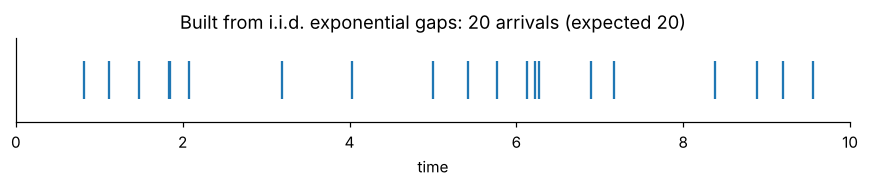

In [8]:
#| fig-height: 2
lam, T = 2.0, 10.0
arr = np.cumsum(rng.exponential(1 / lam, size=500)); arr = arr[arr <= T]
fig, ax = plt.subplots(figsize=(8, 1.8))
ax.eventplot(arr, lineoffsets=0, linelengths=0.8)
ax.set_yticks([]); ax.set_xlim(0, T); ax.set_xlabel("time")
ax.set_title(f"Built from i.i.d. exponential gaps: {len(arr)} arrivals (expected {lam*T:.0f})")
plt.tight_layout(); plt.show()

## The $k$th arrival time

::: {.callout-note}
## Definition

$$T_k=Y_1+Y_2+\cdots+Y_k,$$
a sum of $k$ i.i.d. Exponential$(\lambda)$ interarrival times.
:::

. . .

::: {.callout-tip}
## Properties (Erlang distribution)

$$f_{T_k}(y)=\frac{\lambda^ky^{k-1}e^{-\lambda y}}{(k-1)!},\quad y\ge0,\qquad E[T_k]=\frac k\lambda,\qquad\text{Var}(T_k)=\frac{k}{\lambda^2}.$$
:::

. . .

::: {.callout-warning}
## Derivation sketch

For a small $\delta$: $f_{T_k}(y)\,\delta\approx P(k-1\text{ arrivals in }[0,y])\cdot\lambda\delta=\dfrac{(\lambda y)^{k-1}e^{-\lambda y}}{(k-1)!}\lambda\delta.$

Mean and variance follow from the sum of $k$ i.i.d. exponentials.
:::

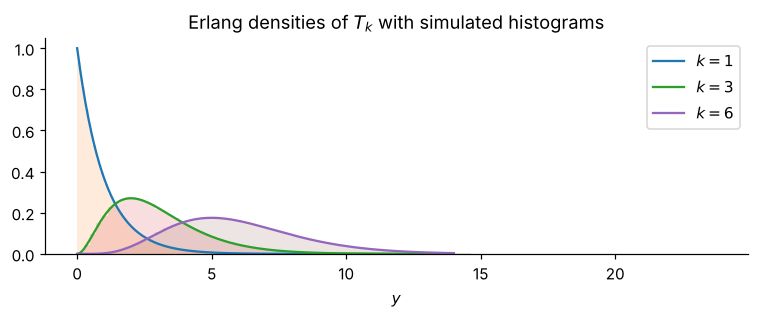

In [9]:
#| fig-height: 3
lam = 1.0
y = np.linspace(0, 14, 400)
sims = {k: rng.gamma(shape=k, scale=1/lam, size=100_000) for k in [1, 3, 6]}
fig, ax = plt.subplots(figsize=(7, 3))
for k, s in sims.items():
    ax.plot(y, stats.gamma.pdf(y, a=k, scale=1/lam), label=f"$k={k}$")   # Erlang = Gamma with integer shape
    ax.hist(s, bins=80, density=True, alpha=0.15)
ax.set_xlabel("$y$"); ax.set_title("Erlang densities of $T_k$ with simulated histograms"); ax.legend()
plt.tight_layout(); plt.show()

## Example: IRS hotline

::: {.callout-warning}
## Example

Calls arrive at the IRS hotline as a Poisson process with rate $\lambda=0.5$ per minute.

(a) What are the mean and standard deviation of the time of the 4th call?

(b) What is the probability that the 3rd call arrives after minute 4?
:::

. . .

::: {.callout-note}
## Solution

(a) $E[T_4]=4/0.5=8$ minutes and $\text{SD}(T_4)=\sqrt4/0.5=4$ minutes.

(b) $T_3>4$ exactly when at most 2 calls arrive in $[0,4]$. With $\lambda\tau=2$,
$$P(T_3>4)=P(N_4\le2)=e^{-2}\left(1+2+\tfrac{2^2}{2}\right)=5e^{-2}\approx0.677.$$
:::

In [10]:
print("P(N_4 <= 2)          =", stats.poisson.cdf(2, 2.0))
print("P(T_3 > 4) (Erlang)  =", stats.gamma.sf(4, a=3, scale=1/0.5))
print("E[T_4], SD(T_4)      =", 4/0.5, 2/0.5)

P(N_4 <= 2)          = 0.6766764161830634
P(T_3 > 4) (Erlang)  = 0.6766764161830634
E[T_4], SD(T_4)      = 8.0 4.0


## Exercise

::: {.callout-caution}
## Exercise

Customers arrive at a shop as a Poisson process with rate $\lambda=6$ per hour.

(a) What is the probability that exactly 2 customers arrive in the next 20 minutes?

(b) What is the expected time until the 3rd customer arrives?

(c) No one has arrived in the last 10 minutes. What is the probability that no one arrives in the next 10 minutes?
:::

. . .

::: {.callout-note}
## Solution

(a) $\lambda\tau=6\cdot\tfrac13=2$, so $P=\dfrac{2^2e^{-2}}{2!}=2e^{-2}\approx0.271$.

(b) $E[T_3]=3/6=0.5$ hours $=30$ minutes.

(c) By memorylessness, $e^{-6\cdot(1/6)}=e^{-1}\approx0.368$; the past 10 minutes are irrelevant.
:::

# Splitting and Merging

## Splitting

::: {.callout-note}
## Splitting

Each arrival of a Poisson$(\lambda)$ process is independently labeled **type A** with probability $p$ and type B otherwise.
:::

. . .

::: {.callout-tip}
## Result

Type A and type B arrivals are **independent Poisson processes** with rates
$$\lambda_A=p\lambda,\qquad\lambda_B=(1-p)\lambda.$$
:::

. . .

::: {.callout-warning}
## Intuition

In a tiny slot, $P(\text{type A arrival})=\lambda\delta\cdot p$, and slots remain independent.
:::

## Merging

::: {.callout-note}
## Merging

Combine two **independent** Poisson processes with rates $\lambda_1$ and $\lambda_2$ into a single stream.
:::

. . .

::: {.callout-tip}
## Result

The merged process is Poisson with rate $\lambda_1+\lambda_2$, and each arrival independently comes from process 1 with probability
$$\frac{\lambda_1}{\lambda_1+\lambda_2}.$$
:::

. . .

::: {.callout-warning}
## Why

In a tiny slot, $P(\text{arrival from either})\approx(\lambda_1+\lambda_2)\delta$. Equivalently, the first arrival time is the minimum of two independent exponentials, which is Exponential$(\lambda_1+\lambda_2)$.
:::

In [11]:
lam1, lam2 = 2.0, 3.0
a = rng.exponential(1 / lam1, 1_000_000); b = rng.exponential(1 / lam2, 1_000_000)
m = np.minimum(a, b)
print("E[min]        :", m.mean(), "  theory", 1 / (lam1 + lam2))
print("P(process 1 first):", (a < b).mean(), "  theory", lam1 / (lam1 + lam2))

E[min]        : 0.1999674836969569   theory 0.2
P(process 1 first): 0.399831   theory 0.4


## Example: mail packages at the post office

::: {.callout-warning}
## Example

Packages are mailed as a Poisson process with rate 10 per hour. Each package is domestic with probability 0.7 and international with probability 0.3, independently.

(a) What is the probability of no international packages in 30 minutes?

(b) Given that 4 packages arrived in an hour, what is the probability that exactly 1 is international?
:::

. . .

::: {.callout-note}
## Solution

By splitting, domestic packages are Poisson with rate 7 per hour and international packages are Poisson with rate 3 per hour, independent of each other.

(a) $e^{-3(0.5)}=e^{-1.5}\approx0.223$.

(b) Each of the 4 packages is international independently with probability 0.3, so
$\binom41(0.3)(0.7)^3\approx0.412$.
:::

In [12]:
print("(a)", stats.poisson.pmf(0, 3 * 0.5))
print("(b)", stats.binom.pmf(1, 4, 0.3))

(a) 0.22313016014842982
(b) 0.4116000000000001


# Sums of a Random Number of RVs

## Summary

::: {.callout-note}
## Setup

Let $Y=X_1+\cdots+X_N$, where $N$ is a nonnegative integer-valued random variable and the $X_i$ are i.i.d. and independent of $N$.
:::

. . .

::: {.callout-tip}
## Summary

| | Formula |
|---|---|
| Mean | $E[Y]=E[N]\,E[X]$ |
| Variance | $\text{Var}(Y)=E[N]\,\text{Var}(X)+(E[X])^2\,\text{Var}(N)$ |
| Transform | $M_Y(s)=M_N\!\left(\ln M_X(s)\right)$ |
:::

. . .

::: {.callout-warning}
## Where it comes from

Condition on $N$: $E[Y\mid N]=N\,E[X]$ and $\text{Var}(Y\mid N)=N\,\text{Var}(X)$, then apply the law of iterated expectation and the law of total variance from Lecture 10.
:::

In [13]:
# Check with N ~ Poisson(4) arrivals and X ~ Exponential(mean 2) sizes
EN, VN = 4.0, 4.0; EX, VX = 2.0, 4.0
Ns = rng.poisson(EN, size=100_000)
Y = np.array([rng.exponential(EX, n).sum() for n in Ns])
print("E[Y]  :", Y.mean(), "  theory", EN * EX)
print("Var(Y):", Y.var(),  "  theory", EN * VX + EX**2 * VN)

E[Y]  : 8.015803144306114   theory 8.0
Var(Y): 32.299057710302804   theory 32.0


# Random Incidence Paradox

## Motivation

::: {.callout-warning}
## Example

Buses arrive as a Poisson process with rate $\lambda$, so the average gap between buses is $1/\lambda$. You arrive at a random time. How long is the gap you land in?
:::

. . .

::: {.callout-note}
## Looking forward and backward

- Time until the next bus: Exponential$(\lambda)$ with mean $1/\lambda$ (fresh start).
- Time since the last bus: also Exponential$(\lambda)$ with mean $1/\lambda$ (run the process backward in time).
:::

. . .

::: {.callout-caution}
## The paradox

The gap containing your arrival has mean about $2/\lambda$, **twice** the average gap.
:::

. . .

::: {.callout-tip}
## Resolution

Random times are more likely to land in **long** gaps. This is length-biased sampling, so the gap you observe is not a typical one.
:::

## Example

::: {.callout-warning}
## Example

Gaps between buses are 5 minutes or 15 minutes, each with probability $\tfrac12$, so the average gap is 10 minutes. What is the average gap seen by a random arriver?
:::

. . .

::: {.callout-note}
## Solution

A random arrival lands in a 5-minute gap with probability $\frac{5}{5+15}=0.25$ and in a 15-minute gap with probability $0.75$:
$$E[\text{observed gap}]=0.25(5)+0.75(15)=12.5\text{ minutes}>10.$$
In general, $E[\text{observed gap}]=\dfrac{E[Y^2]}{E[Y]}$, which for Exponential$(\lambda)$ gaps is $\dfrac{2/\lambda^2}{1/\lambda}=\dfrac2\lambda$.
:::

In [14]:
lam = 0.1                                       # average gap = 10 minutes
arr = np.cumsum(rng.exponential(1 / lam, size=200_000))
obs = rng.uniform(arr[10], arr[-10], size=50_000)
idx = np.searchsorted(arr, obs)
seen = arr[idx] - arr[idx - 1]
print("average gap, over all gaps       :", np.diff(arr).mean())
print("average gap seen by random arriver:", seen.mean(), "  theory 2/lambda =", 2 / lam)

average gap, over all gaps       : 9.979110349734823
average gap seen by random arriver: 20.02804287255538   theory 2/lambda = 20.0
